**MNIST MLP AE**：完成第 7-10 节，画出原图与重建图。

在这个笔记中我们只重塑特征图像，对标签不做任何使用

In [48]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms

In [4]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: mps


In [49]:
# 1、加载数据
transform = transforms.ToTensor()
train_set_src = datasets.MNIST(
    root="../../data/dl",
    train=True,
    download=True,
    transform=transform,
)
test_set = datasets.MNIST(
    root="../../data/dl",
    train=False,
    download=True,
    transform=transform,
)

train_set, valid_set = random_split(train_set_src, [55000, 5000], generator=torch.Generator().manual_seed(23))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape, labels.shape)



torch.Size([128, 1, 28, 28]) torch.Size([128])


In [50]:
# 2、定义数据集
class ImageOnlyDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, index):
        images, labels = self.dataset[index]
        return images
# x = torch.tensor([[1,2,3], [4,5,6], [7,8,9]])
test_iod = ImageOnlyDataset(train_set)
print(test_iod)
print(len(test_iod))
print(test_iod[0].shape)


55000
torch.Size([1, 28, 28])


In [51]:
# 3. 全连接自编码器的结构与 shape
# `nn.Linear` 处理二维输入 `[N, D]`，所以图片先需要展平为 `[N, 784]`，最后再恢复为 `[N, 1, 28, 28]`。这里使用 32 维潜在向量：

class MLPAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super(MLPAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), # [N, 1,28,28] -> [N, 28 * 28]
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def encode(self, x):
        return self.encoder(x)
    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x)
        # print(z.shape)
        x_hat = self.decode(z)
        # print(x_hat.shape)
        return x_hat

tmp_x = torch.randn(8, 1, 28, 28).to(device)
tmp_model = MLPAutoencoder().to(device)
tmp_output = tmp_model(tmp_x)
print(tmp_output.shape)
z = tmp_model.encode(tmp_x)
print(z.shape)
x_hat = tmp_model.decode(z)
print(x_hat.shape)


torch.Size([8, 1, 28, 28])
torch.Size([8, 32])
torch.Size([8, 1, 28, 28])


In [52]:
# 4、训练模型
model = MLPAutoencoder(latent_dim=32).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_losses, valid_losses = [], []

best_loss = float("inf")
best_model_state_dict = None

epochs = 50
for epoch in range(epochs):
    model.train()

    train_sample = 0
    train_loss_sum = 0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, images)
        loss.backward()
        optimizer.step()

        size = images.shape[0]
        train_sample += size
        train_loss_sum += loss.item() * size
    train_loss = train_loss_sum / train_sample
    train_losses.append(train_loss)

    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    with torch.no_grad():
        for images, _ in valid_loader:
            images = images.to(device)
            outputs = model(images)
            loss = criterion(outputs, images)
            size = images.shape[0]
            valid_sample += size
            valid_loss_sum += loss.item() * size

    valid_loss = valid_loss_sum / valid_sample
    valid_losses.append(valid_loss)

    if valid_loss < best_loss:
        best_loss = valid_loss
        best_model_state_dict = copy.deepcopy(model.state_dict())

    if (epoch+1) % 10 == 0:
        print(f"Epoch: {epoch + 1}, train loss: {train_loss:.4f}, valid loss: {valid_loss:.4f}")

print("Finished Training")
print(f"Best valid loss: {best_loss:.4f}")
torch.save(best_model_state_dict, "../../data/output/MLPAutoencoder_best_model_state_dict.pth")



Epoch: 10, train loss: 0.0097, valid loss: 0.0095
Epoch: 20, train loss: 0.0069, valid loss: 0.0072
Epoch: 30, train loss: 0.0058, valid loss: 0.0061
Epoch: 40, train loss: 0.0052, valid loss: 0.0056
Epoch: 50, train loss: 0.0048, valid loss: 0.0052
Finished Training
Best valid loss: 0.0052


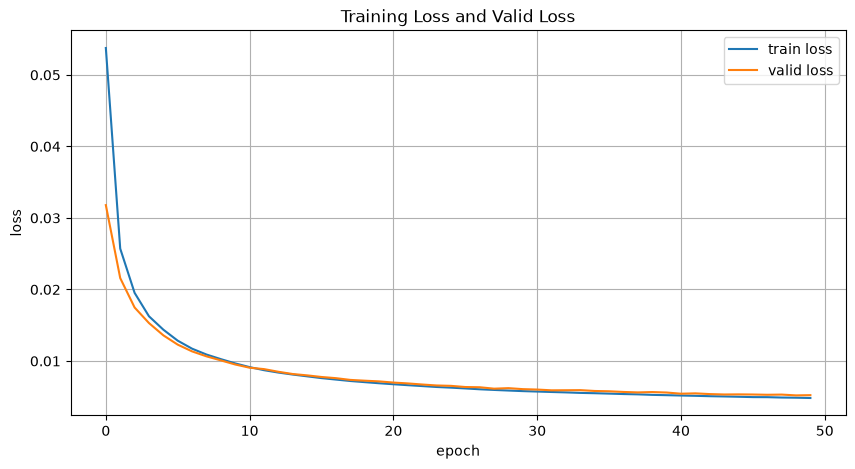

In [53]:
# 损失可视化
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="train loss")
plt.plot(valid_losses, label="valid loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training Loss and Valid Loss")
plt.legend()
plt.grid(True)
plt.show()

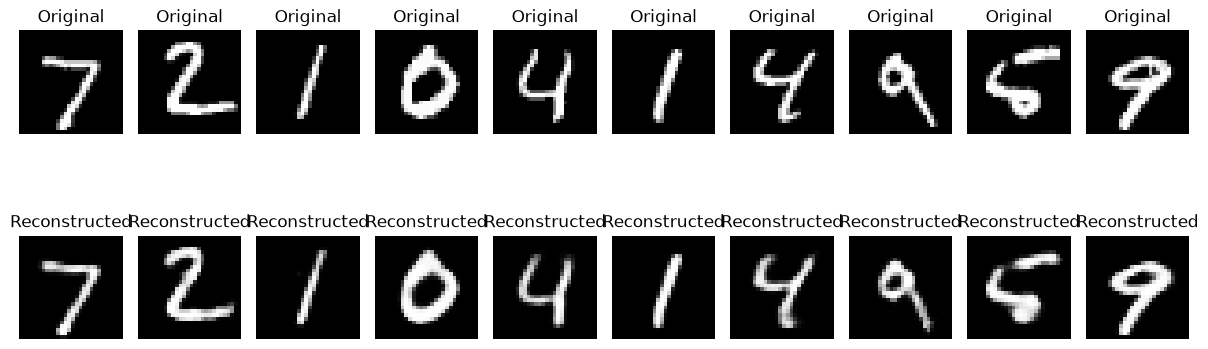

In [54]:
# 使用训练好的最佳模型进行预测

best_model = MLPAutoencoder(latent_dim=32).to(device)
load_best_model_state_dict = torch.load("../../data/output/MLPAutoencoder_best_model_state_dict.pth")
best_model.load_state_dict(best_model_state_dict)

best_model.eval()

show_num = 10

with torch.inference_mode():
    images, _ = next(iter(test_loader))
    images = images[:show_num].to(device)
    reconstructed = best_model(images)

fig, axes = plt.subplots(2, show_num, figsize=(12, 5))

for i in range(show_num):
    axes[0, i].imshow(images[i].squeeze().cpu().numpy(), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].squeeze().cpu().numpy(), cmap="gray")
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 从测试集里面划分出验证集
#